# Pre-Procesamiento de Datos

In [2]:
import pandas as pd
from utils import get_data
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import re


Matplotlib is building the font cache; this may take a moment.


Una vista al dataset:

In [3]:
# Leemos el dataset
df = get_data()

df.head()

,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
0,10365064,HZ100370,2015-12-31 23:59:00,075XX S EMERALD AVE,1320,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,...,17.0,68.0,14,1172605.0,1854931.0,2015,2018-02-10 15:50:01,41.757367,-87.642993,POINT (-87.642992854 41.757366519)
1,10460641,HZ199559,2015-12-31 23:59:00,015XX N KEDZIE AVE,0890,THEFT,FROM BUILDING,RESIDENCE PORCH/HALLWAY,False,False,...,26.0,23.0,06,NaN,NaN,2015,2018-02-09 15:44:29,NaN,NaN,NaN
2,10364662,HZ100006,2015-12-31 23:55:00,079XX S STONY ISLAND AVE,0430,BATTERY,AGGRAVATED: OTHER DANG WEAPON,STREET,False,False,...,8.0,45.0,04B,1188223.0,1852840.0,2015,2018-02-10 15:50:01,41.751270,-87.585822,POINT (-87.585822373 41.751270452)
3,10364740,HZ100010,2015-12-31 23:50:00,024XX W FARGO AVE,0820,THEFT,$500 AND UNDER,APARTMENT,False,False,...,50.0,2.0,06,1158878.0,1949369.0,2015,2018-02-10 15:50:01,42.016804,-87.690709,POINT (-87.690708662 42.016804165)
4,10364683,HZ100002,2015-12-31 23:50:00,037XX N CLARK ST,0460,BATTERY,SIMPLE,SIDEWALK,True,False,...,44.0,6.0,08B,1167786.0,1925033.0,2015,2018-02-10 15:50:01,41.949837,-87.658635,POINT (-87.658635101 41.949837364)


In [4]:
# Eliminamos las variables redundantes para dejar solo los features
df = df.drop([
    # Identificadores
    'ID',

    # Fue asignado posterior al hecho
    'Updated On',

    # Tiene el mismo valor para todas las filas
    'Year',

    # Redundantes con respecto a X Coordinate y Y Coordinate
    'Latitude',
    'Longitude',
    'Location',
], axis=1)

# Eliminamos date y cambiamos por month, day, hour y weekday
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['Hour'] = df['Date'].dt.hour
df['Weekday'] = df['Date'].dt.weekday

# Indicadores de fecha/hora default. Cuando no se conoce la hora real,
# el hecho se registra a las 00:00. Si no se conoce el día, se usa el día 1 del mes

df['hora_default'] = (df['Date'].dt.hour == 0) & (df['Date'].dt.minute == 0)
df['fecha_default'] = df['hora_default'] & (df['Date'].dt.day == 1)

df = df.drop(['Date'], axis=1)

Vamos a investigar crímenes que aparecen duplicados en el dataset. 

In [5]:
df_duplicates = df[df.duplicated(subset=['Case Number'], keep=False)]

display(df_duplicates.head())
display(df_duplicates['Primary Type'].value_counts())
rows = df.shape[0]

,Case Number,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,...,Community Area,FBI Code,X Coordinate,Y Coordinate,Month,Day,Hour,Weekday,hora_default,fecha_default
2840,HY551250,059XX S WENTWORTH AVE,0110,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,232,2,...,68.0,01A,1175978.0,1865746.0,12,27,6,6,False,False
2910,HY551250,059XX S WENTWORTH AVE,0110,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,232,2,...,68.0,01A,1175978.0,1865746.0,12,27,2,6,False,False
66152,HY442430,003XX W 42ND ST,0110,HOMICIDE,FIRST DEGREE MURDER,PARK PROPERTY,True,False,925,9,...,37.0,01A,1174451.0,1877100.0,9,29,3,1,False,False
66177,HY442430,003XX W 42ND ST,0110,HOMICIDE,FIRST DEGREE MURDER,PARK PROPERTY,True,False,925,9,...,37.0,01A,1174451.0,1877100.0,9,29,1,1,False,False
66188,HY442430,003XX W 42ND ST,0110,HOMICIDE,FIRST DEGREE MURDER,PARK PROPERTY,True,False,925,9,...,37.0,01A,1174451.0,1877100.0,9,29,1,1,False,False


Primary Type
HOMICIDE    50
Name: count, dtype: int64

Corresponden a homicidios múltiples (Ver [About Data](https://data.cityofchicago.org/Public-Safety/Crimes-2001-to-Present/ijzp-q8t2/about_data)). Vamos a verificar si vale la pena conservar esta información.

Podríamos crear algo así de forma directa:

```python
# Antes de dropear 'Case Number': conservamos la info de víctimas múltiples
case_size = df.groupby('Case Number')['Case Number'].transform('size')
df_unique['MULTIPLE_VICTIMS'] = (case_size > 1)
```

Pero hay que considerar a qué porcentaje del dataset corresponde esta información. Si es un porcentaje muy bajo, no vale la pena conservarla.

In [6]:
display(df['Primary Type'].value_counts())
display(df.shape)

Primary Type
THEFT                                57355
BATTERY                              48927
CRIMINAL DAMAGE                      28677
NARCOTICS                            23939
OTHER OFFENSE                        17566
ASSAULT                              17048
DECEPTIVE PRACTICE                   16502
BURGLARY                             13184
MOTOR VEHICLE THEFT                  10068
ROBBERY                               9638
CRIMINAL TRESPASS                     6401
WEAPONS VIOLATION                     3364
OFFENSE INVOLVING CHILDREN            2527
PUBLIC PEACE VIOLATION                2422
PROSTITUTION                          1322
CRIM SEXUAL ASSAULT                   1319
INTERFERENCE WITH PUBLIC OFFICER      1308
SEX OFFENSE                           1054
HOMICIDE                               502
ARSON                                  453
GAMBLING                               310
LIQUOR LAW VIOLATION                   292
KIDNAPPING                             19

(264910, 21)

Vamos a crear de forma sintética un NUM_VICTIMS, que nos indique la cantidad de víctimas por caso. Esto nos permitirá analizar si es relevante o no conservar esta información.

In [7]:
# Los Case Number repetidos son homicidios con múltiples víctimas:
# cada fila representa una víctima del mismo caso (27 casos, 50 filas — ver EDA).
# Trabajamos a nivel de caso, conservando una fila por Case Number.
df_unique = df.drop_duplicates(subset=['Case Number'], keep='first')

# Agregamos información de cantidad de víctimas por caso.
case_size = df.groupby('Case Number')['Case Number'].transform('size')
df_unique['NUM_VICTIMS'] = case_size
display(df_unique.head())

# Check df where NUM_VICTIMS > 1
display(df_unique[df_unique['NUM_VICTIMS'] > 1].head())

,Case Number,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,...,FBI Code,X Coordinate,Y Coordinate,Month,Day,Hour,Weekday,hora_default,fecha_default,NUM_VICTIMS
0,HZ100370,075XX S EMERALD AVE,1320,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,621,6,...,14,1172605.0,1854931.0,12,31,23,3,False,False,1
1,HZ199559,015XX N KEDZIE AVE,0890,THEFT,FROM BUILDING,RESIDENCE PORCH/HALLWAY,False,False,1422,14,...,06,NaN,NaN,12,31,23,3,False,False,1
2,HZ100006,079XX S STONY ISLAND AVE,0430,BATTERY,AGGRAVATED: OTHER DANG WEAPON,STREET,False,False,411,4,...,04B,1188223.0,1852840.0,12,31,23,3,False,False,1
3,HZ100010,024XX W FARGO AVE,0820,THEFT,$500 AND UNDER,APARTMENT,False,False,2411,24,...,06,1158878.0,1949369.0,12,31,23,3,False,False,1
4,HZ100002,037XX N CLARK ST,0460,BATTERY,SIMPLE,SIDEWALK,True,False,1923,19,...,08B,1167786.0,1925033.0,12,31,23,3,False,False,1


,Case Number,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,...,FBI Code,X Coordinate,Y Coordinate,Month,Day,Hour,Weekday,hora_default,fecha_default,NUM_VICTIMS
2840,HY551250,059XX S WENTWORTH AVE,0110,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,232,2,...,01A,1175978.0,1865746.0,12,27,6,6,False,False,2
66152,HY442430,003XX W 42ND ST,0110,HOMICIDE,FIRST DEGREE MURDER,PARK PROPERTY,True,False,925,9,...,01A,1174451.0,1877100.0,9,29,3,1,False,False,3
66379,HY442160,053XX S ABERDEEN ST,0110,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,934,9,...,01A,1169890.0,1869399.0,9,28,20,0,False,False,2
86976,HY406845,050XX N WINTHROP AVE,0110,HOMICIDE,FIRST DEGREE MURDER,STREET,True,False,2024,20,...,01A,1167957.0,1933812.0,9,2,2,2,False,False,2
90101,HY402004,052XX S LOREL AVE,0110,HOMICIDE,FIRST DEGREE MURDER,HOUSE,False,False,814,8,...,01A,1141580.0,1869447.0,8,29,9,5,False,False,2


Los homicidios múltiples corresponden a un 10% de los casos de homicidio.
Ahora estos corresponden a un 0.01% de los casos totales. Por lo tanto, consideramos que no vale la pena conservar esta información (**pero vale tenerlo en consideración**).

In [8]:
# We drop Case Number and keep only the first occurrence of each case to avoid duplicates in the dataset.
# We ingore the victims count for the analysis since they too unfrequent (only 27 cases with multiple victims).
df = df.drop_duplicates(subset=['Case Number'], keep='first')
df = df.drop(['Case Number'], axis=1)

## Unión de SEXUAL ASSAULT

En el dataset se definen dos Primary Types para un mismo crimen: `CRIM SEXUAL ASSAULT` y `CRIMINAL SEXUAL ASSAULT`.

In [9]:
# Mostramos todos los primary types que contienen "SEXUAL ASSAULT"
primary_types = pd.Series(df['Primary Type'].unique())
display(primary_types[primary_types.str.contains('SEXUAL ASSAULT')])

7     CRIMINAL SEXUAL ASSAULT
11        CRIM SEXUAL ASSAULT
dtype: str

Veamos qué códigos IUCR y FBI se usan para cada uno de estos dos tipos, para verificar si comparten los mismos códigos:

In [10]:
sa = df[df['Primary Type'].str.contains('SEXUAL ASSAULT', na=False)]

# Ambos tipos comparten el mismo código FBI
display(sa.groupby('Primary Type')['FBI Code'].agg(lambda s: ', '.join(s.unique())))

# Los códigos IUCR se solapan: los 6 códigos de CRIMINAL SEXUAL ASSAULT
# también aparecen en CRIM SEXUAL ASSAULT (que tiene 6 adicionales)
display(pd.crosstab(sa['IUCR'], sa['Primary Type'], margins=True))

Primary Type
CRIM SEXUAL ASSAULT        02
CRIMINAL SEXUAL ASSAULT    02
Name: FBI Code, dtype: str

Primary Type,CRIM SEXUAL ASSAULT,CRIMINAL SEXUAL ASSAULT,All
IUCR,,,
0261,47,8,55
0262,3,0,3
0263,32,4,36
0264,11,0,11
0265,169,17,186
0266,155,51,206
0271,5,0,5
0273,3,0,3
0274,1,0,1


Como comparten el mismo código FBI (`02`) y sus códigos IUCR se solapan, unificamos ambos tipos en un único Primary Type: `SEXUAL ASSAULT`.

In [11]:
# Unificamos los dos tipos en df
df['Primary Type'] = df['Primary Type'].replace({
    'CRIM SEXUAL ASSAULT': 'SEXUAL ASSAULT',
    'CRIMINAL SEXUAL ASSAULT': 'SEXUAL ASSAULT',
})

# Verificamos que quede un único tipo para este crimen
display(df[df['Primary Type'] == 'SEXUAL ASSAULT']['Primary Type'].value_counts())

Primary Type
SEXUAL ASSAULT    1467
Name: count, dtype: int64

## Limpieza de NON-CRIMINAL

Existe un reporte de NON-CRIMINAL. Dado que el dataset es de crímenes, esto solo es ruido y vamos a eliminarlo.

In [12]:
# Mostramos todos los primary types que contienen "NON"
# (en el dataset, solo las variantes de NON-CRIMINAL lo contienen)
primary_types = pd.Series(df['Primary Type'].unique())
non_criminal_types = primary_types[primary_types.str.contains('NON', na=False)]
display(non_criminal_types)

# Vemos cuántas filas corresponden a cada variante
display(df[df['Primary Type'].isin(non_criminal_types)]['Primary Type'].value_counts())


30    NON-CRIMINAL
dtype: str

Primary Type
NON-CRIMINAL    1
Name: count, dtype: int64

In [13]:
# Eliminamos el único reporte con Primary Type == 'NON-CRIMINAL' (ver celda anterior)
# No corresponde a un crimen
df = df[df['Primary Type'] != 'NON-CRIMINAL']

# Verificamos que no queden filas de este tipo
display(df[df['Primary Type'] == 'NON-CRIMINAL'].shape[0])


0

## Limpieza de FBI Code e IUCR Code

Medimos la asociación (V de Cramér con corrección de Bergsma, 2013) entre la combinación `Primary Type | Description` y cada código, y la resumimos en una matriz de asociación.

Cardinalidades:
Primary Type | Description    366
FBI Code                       26
IUCR                          328


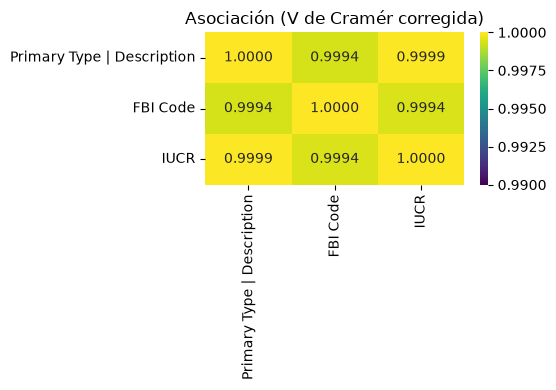

Máximo de códigos FBI por combinación: 1
Máximo de códigos IUCR por combinación: 1
Máximo de combinaciones por IUCR: 2 (38 IUCR afectados)


IUCR
0261    SEXUAL ASSAULT | AGGRAVATED: HANDGUN, SEXUAL A...
0263    SEXUAL ASSAULT | AGGRAVATED: KNIFE/CUT INSTR, ...
0265    SEXUAL ASSAULT | AGGRAVATED: OTHER, SEXUAL ASS...
0312    ROBBERY | ARMED:KNIFE/CUTTING INSTRUMENT, ROBB...
Name: Primary Type | Description, dtype: str

In [14]:
# Medimos la asociación entre la combinación Primary Type + Description y los códigos FBI e IUCR

def cramers_v(x, y):
    """V de Cramér con corrección por sesgo (Bergsma, 2013)."""
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = chi2 / n
    # La corrección evita sobrestimar la asociación en tablas con muchas categorías
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / min(kc - 1, rc - 1))


# Columna temporal que combina Primary Type y Description
pt_desc = df['Primary Type'] + ' | ' + df['Description']
codigos = pd.DataFrame({
    'Primary Type | Description': pt_desc,
    'FBI Code': df['FBI Code'],
    'IUCR': df['IUCR'],
})
print(f"Cardinalidades:\n{codigos.nunique().to_string()}")

# Matriz de asociación (V de Cramér) entre las tres variables
vars_cat = codigos.columns.to_list()
matriz = pd.DataFrame(
    [[cramers_v(codigos[a], codigos[b]) for b in vars_cat] for a in vars_cat],
    index=vars_cat, columns=vars_cat,
)
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(matriz, annot=True, fmt='.4f', cmap='viridis', vmin=0.99, vmax=1, ax=ax)
ax.set_title('Asociación (V de Cramér corregida)')
plt.tight_layout()
plt.show()

# Dirección de la relación: ¿cada combinación mapea a un único código?
por_combo = codigos.groupby('Primary Type | Description')[['FBI Code', 'IUCR']].nunique()
print(f"Máximo de códigos FBI por combinación: {por_combo['FBI Code'].max()}")
print(f"Máximo de códigos IUCR por combinación: {por_combo['IUCR'].max()}")

# En el sentido inverso: ¿algún IUCR abarca más de una combinación?
combos_por_iucr = codigos.groupby('IUCR')['Primary Type | Description'].nunique()
print(f"Máximo de combinaciones por IUCR: {combos_por_iucr.max()} "
      f"({(combos_por_iucr > 1).sum()} IUCR afectados)")
multi = combos_por_iucr[combos_por_iucr > 1].index
display(codigos[codigos['IUCR'].isin(multi)]
        .groupby('IUCR')['Primary Type | Description'].agg(lambda x: ', '.join(x.unique())).head(4))

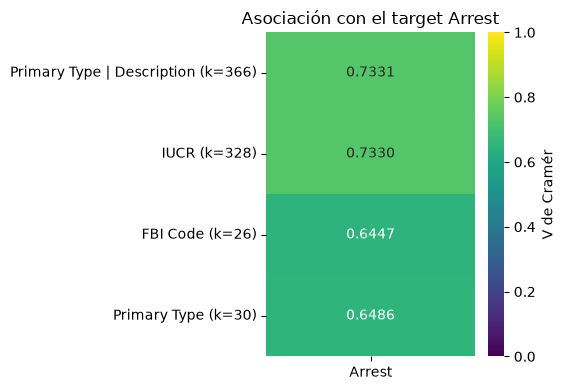

In [15]:
# Comparamos cuánta asociación con el target Arrest conserva cada codificación
# (análisis exploratorio para la selección de features; la decisión fina se valida con CV)
arrest = df['Arrest'].astype(int)
candidatas = {
    'Primary Type | Description': pt_desc,
    'IUCR': df['IUCR'],
    'FBI Code': df['FBI Code'],
    'Primary Type': df['Primary Type'],
}

# Misma comparación, resumida en una matriz de una columna (una fila por codificación)
matriz_arrest = pd.DataFrame(
    {'Arrest': [cramers_v(arrest, col) for col in candidatas.values()]},
    index=[f"{nombre} (k={col.nunique()})" for nombre, col in candidatas.items()],
)
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(matriz_arrest, annot=True, fmt='.4f', cmap='viridis', vmin=0, vmax=1,
            cbar_kws={'label': 'V de Cramér'}, ax=ax)
ax.set_title('Asociación con el target Arrest')
plt.tight_layout()
plt.show()

**Conclusiones.** Tanto `FBI Code` (26 categorías) como `IUCR` (328) muestran una asociación prácticamente perfecta con `Primary Type | Description` (`V ≈ 1` en la matriz), y cada combinación mapea a un único código: la relación es determinista en un solo sentido.

- `FBI Code` es una agrupación más gruesa de `Primary Type + Description`; no aporta información nueva (ej: el código `26` agrupa 12 Primary Types distintos).

- Contra el target, la combinación concentra más señal (`V(Arrest) = 0.733`) que `FBI Code` (0.645) e incluso que `Primary Type` solo (0.649); dentro de un mismo código FBI la tasa de arresto varía hasta 100 pp. Su mayor cardinalidad no justifica perder esa información: la estrategia de encoding se decide más adelante.

Conservamos `Primary Type + Description` y eliminamos ambos códigos.

In [16]:
# Eliminamos ambos códigos: son redundantes con Primary Type + Description
df = df.drop(['FBI Code', 'IUCR'], axis=1)
display(df.shape)

(264882, 18)

In [17]:
df.head()

,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,X Coordinate,Y Coordinate,Month,Day,Hour,Weekday,hora_default,fecha_default
0,075XX S EMERALD AVE,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,621,6,17.0,68.0,1172605.0,1854931.0,12,31,23,3,False,False
1,015XX N KEDZIE AVE,THEFT,FROM BUILDING,RESIDENCE PORCH/HALLWAY,False,False,1422,14,26.0,23.0,NaN,NaN,12,31,23,3,False,False
2,079XX S STONY ISLAND AVE,BATTERY,AGGRAVATED: OTHER DANG WEAPON,STREET,False,False,411,4,8.0,45.0,1188223.0,1852840.0,12,31,23,3,False,False
3,024XX W FARGO AVE,THEFT,$500 AND UNDER,APARTMENT,False,False,2411,24,50.0,2.0,1158878.0,1949369.0,12,31,23,3,False,False
4,037XX N CLARK ST,BATTERY,SIMPLE,SIDEWALK,True,False,1923,19,44.0,6.0,1167786.0,1925033.0,12,31,23,3,False,False


## Limpieza de Localidades

Vamos a considerar la limpieza de variables que están asociadas a localidades:
- Block
- Location Description
- Beat
- District
- Ward
- Community Area

Cardinalidades:
Block                   27522
Location Description      140
Beat                      274
District                   23
Ward                       50
Community Area             77


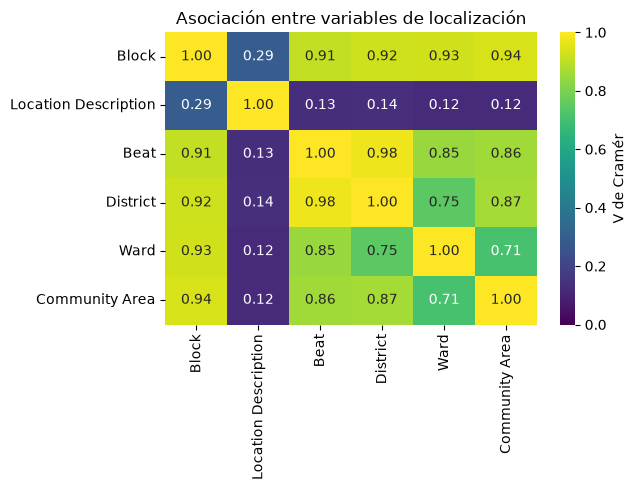

Beats que cruzan más de un distrito: 30 de 274
Máximo de community areas por ward: 10
Máximo de wards por community area: 8
Máximo de beats por block: 4


In [18]:
# Medimos la asociación entre las variables de localización para detectar redundancia,
# con la misma V de Cramér corregida (Bergsma, 2013) de la sección anterior.
# Única excepción: la diagonal de Block se fija en 1 (con k ≈ 27 mil categorías, la tabla
# de contingencia densa de ese par no es computable y el valor trivial no aporta nada).

localizacion = ['Block', 'Location Description', 'Beat', 'District', 'Ward', 'Community Area']
print(f"Cardinalidades:\n{df[localizacion].nunique().to_string()}")

# Matriz simétrica: cada par se calcula una sola vez y se espeja
matriz = pd.DataFrame(index=localizacion, columns=localizacion, dtype=float)
for i, a in enumerate(localizacion):
    matriz.iloc[i, i] = 1.0
    for b in localizacion[i + 1:]:
        v = cramers_v(df[a], df[b])
        matriz.loc[a, b] = v
        matriz.loc[b, a] = v

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(matriz, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1,
            cbar_kws={'label': 'V de Cramér'}, ax=ax)
ax.set_title('Asociación entre variables de localización')
plt.tight_layout()
plt.show()

# ¿Las geografías más finas anidan dentro de las más gruesas?
# (mismo tipo de chequeo de cardinalidad que hicimos con FBI Code / IUCR)
distritos_por_beat = df.groupby('Beat')['District'].nunique()
print(f"Beats que cruzan más de un distrito: {(distritos_por_beat > 1).sum()} de {len(distritos_por_beat)}")

ca_por_ward = df.groupby('Ward')['Community Area'].nunique()
wards_por_ca = df.groupby('Community Area')['Ward'].nunique()
print(f"Máximo de community areas por ward: {ca_por_ward.max()}")
print(f"Máximo de wards por community area: {wards_por_ca.max()}")

beats_por_block = df.groupby('Block')['Beat'].nunique()
print(f"Máximo de beats por block: {beats_por_block.max()}")


**Conclusiones.** Las cinco variables geográficas están fuertemente asociadas entre sí (`V = 0.71–0.98`), mientras que `Location Description` es casi independiente a todas (`V ≈ 0.12–0.14`): describe el tipo de lugar, no la ubicación, así que no es redundante con la geografía.

- `District` es casi un engrosamiento de `Beat` (`V = 0.98`): salvo 30 beats de frontera, cada beat cae en un único distrito. Si se conserva `Beat`, `District` no agrega información.

- `Ward` y `Community Area` se solapan (`V = 0.71`) sin anidarse (hasta 10 community areas por ward y 8 wards por community area): son recortes con lógicas distintas (política vs. histórica).

- `Block` (k ≈ 27.500) es la de mayor resolución y absorbe buena parte de las demás (`V ≈ 0.91–0.94` con las otras geografías).

Hay redundancia alta dentro del bloque geográfico: alcanza con pocas variables de resolución dispar (p. ej. `Block` + `Beat`); la elección concreta se hace al codificar y se valida con CV.


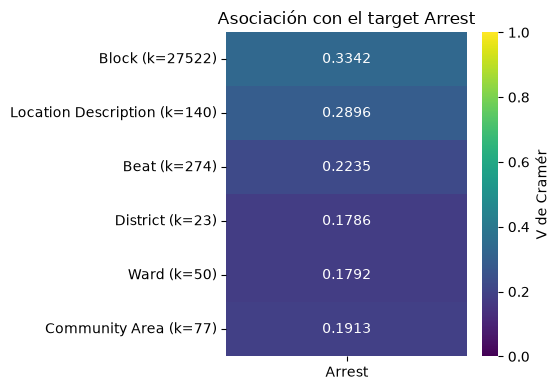

,k,V_corr,V_sin_corr
combinación,,,
TODO (Block|Beat|Dist|CA|Ward),31876,0.3380,0.4843
Block | Beat | CA | Ward,31848,0.3380,0.4842
Block | Beat,29879,0.3374,0.4760
Block | Ward,29499,0.3348,0.4727
Block | Community Area,28222,0.3344,0.4673
Beat | District | CA | Ward,954,0.2383,0.2457
Beat | CA | Ward,923,0.2382,0.2454
Beat | Ward,652,0.2326,0.2378
Beat | Community Area,480,0.2300,0.2339



Block: penalidad de la corrección sobre phi2 = 0.1039; V sin corregir = 0.4643


In [19]:
arrest = df['Arrest'].astype(int)

# A diferencia de la matriz anterior, acá sí podemos calcular Block vs Arrest (la tabla es k x 2)
matriz_arrest = pd.DataFrame(
    {'Arrest': [cramers_v(arrest, df[c]) for c in localizacion]},
    index=[f"{c} (k={df[c].nunique()})" for c in localizacion],
)
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(matriz_arrest, annot=True, fmt='.4f', cmap='viridis', vmin=0, vmax=1,
            cbar_kws={'label': 'V de Cramér'}, ax=ax)
ax.set_title('Asociación con el target Arrest')
plt.tight_layout()
plt.show()

# ¿La variable gruesa aporta algo además de la fina? Extendemos el chequeo a pares cruzados
# entre familias (policial vs. cívica), combinaciones con Block y escaleras incrementales.
# Contra Arrest (binaria) toda tabla es k x 2: incluso las variantes con Block son computables.
# (astype(str) vuelve los pocos NaN de Ward / Community Area una categoría propia, así que
# todas las filas participan en todas las combinaciones.)
S = lambda cols: df[cols[0]].astype(str).str.cat(
    [df[c].astype(str) for c in cols[1:]], sep=' | ')

combinaciones = {
    # ya analizadas en el heatmap
    'Beat': ['Beat'],
    'Community Area': ['Community Area'],
    'Ward': ['Ward'],
    'Beat | District': ['Beat', 'District'],
    'Community Area | Ward': ['Community Area', 'Ward'],
    # pares cruzados entre familias (geografía policial vs. cívica)
    'Beat | Ward': ['Beat', 'Ward'],
    'Beat | Community Area': ['Beat', 'Community Area'],
    'District | Ward': ['District', 'Ward'],
    'District | Community Area': ['District', 'Community Area'],
    # sumando Block (la más fina) a cada familia
    'Block | Beat': ['Block', 'Beat'],
    'Block | Ward': ['Block', 'Ward'],
    'Block | Community Area': ['Block', 'Community Area'],
    # escaleras incrementales: ¿cuánta señal acumula la geografía completa?
    'Beat | CA | Ward': ['Beat', 'Community Area', 'Ward'],
    'Beat | District | CA | Ward': ['Beat', 'District', 'Community Area', 'Ward'],
    'Block | Beat | CA | Ward': ['Block', 'Beat', 'Community Area', 'Ward'],
    'TODO (Block|Beat|Dist|CA|Ward)': ['Block', 'Beat', 'District', 'Community Area', 'Ward'],
}

# Mostramos V corregida y sin corregir: al crecer k, la penalidad de Bergsma
# ((k-1)(r-1)/(n-1)) castiga cada vez más a las columnas combinadas y quedan muchas
# categorías con 1-2 filas. Ordenamos por V sin corregir para comparar entre k dispares.
filas = []
for nombre, cols in combinaciones.items():
    col = S(cols)
    ct = pd.crosstab(arrest, col)
    phi2 = chi2_contingency(ct)[0] / ct.to_numpy().sum()
    filas.append({
        'combinación': nombre,
        'k': col.nunique(),
        'V_corr': cramers_v(arrest, col),
        # target binario => min(k-1, r-1) = 1 => V sin corregir = sqrt(phi2)
        'V_sin_corr': np.sqrt(phi2),
    })
display(pd.DataFrame(filas)
        .sort_values('V_sin_corr', ascending=False)
        .set_index('combinación')
        .round(4))

# La corrección de Bergsma le descuenta a Block una penalidad grande por su cardinalidad:
# le resta (k-1)(r-1)/(n-1) a phi2. Sin corregir, su asociación sería bastante mayor.
ct_block = pd.crosstab(arrest, df['Block'])
phi2_block = chi2_contingency(ct_block)[0] / ct_block.to_numpy().sum()
penalidad = (df['Block'].nunique() - 1) / (ct_block.to_numpy().sum() - 1)
print(f"\nBlock: penalidad de la corrección sobre phi2 = {penalidad:.4f}; "
      f"V sin corregir = {np.sqrt(phi2_block):.4f}")


**Conclusiones.** Toda la geografía porta señal sobre `Arrest` (`V = 0.18–0.33`), y a mayor resolución, mayor señal; `Location Description` no es geografía pero también asocia fuerte (`V = 0.290`, segunda solo detrás de `Block`).

- `Block` es la más asociada (`V = 0.334`), y subestima su señal real: la corrección de Bergsma le descuenta `≈ 0.10` de φ² por su alta cardinalidad (sin corregir sería `0.464`). Las combinaciones que la incluyen (`0.467–0.484` sin corregir) apenas la mejoran: concentra `≈ 96%` de la señal de la geografía completa.

- `District` es la candidata clara a eliminar: tiene la menor asociación con el target (`V = 0.179`) y no agrega nada en ningún escenario: `V(Beat | District) = V(Beat) = 0.224`, y la escalera completa sin ella es prácticamente idéntica (`Block | Beat | CA | Ward = 0.4842` vs `TODO = 0.4843`, sin corregir).

- Fuera de `Block`, la geografía cívica suma un extra acotado: de `Beat` solo (`0.226` sin corregir) a `Beat | CA | Ward` (`0.246`). `Ward` y `Community Area` tampoco son intercambiables entre sí (combinadas suben a `0.209`, vs `0.179` y `0.191` por separado).

En síntesis: eliminamos `District`; `Block` concentra casi toda la señal geográfica (y `Location Description` la del tipo de lugar), el resto queda como candidato a comprimir o descartar en el encoding, a validar con CV.

In [20]:
df = df.drop(['District'], axis=1)

## Local Description Nulos

Vamos a analizar los nulos de `Location Description`. Están asociados a algún crimen en particular?

In [21]:
# ¿Los nulos de `Location Description` están asociados a algún `Primary Type` + `Description`?
# Comparamos la tasa de nulos por combinación y medimos la asociación del indicador
# de nulo contra cada variable con la misma V de Cramér corregida de la sección anterior.
nulos = df['Location Description'].isna()
print(f"Filas con Location Description nula: {nulos.sum()} de {len(df)} ({nulos.mean():.2%})")

# Nulos por combinación: cantidad absoluta y tasa dentro de cada combinación
por_combo = (
    df.assign(nulo=nulos)
      .groupby(['Primary Type', 'Description'])['nulo']
      .agg(nulos='sum', filas='size')
      .assign(tasa=lambda t: t['nulos'] / t['filas'])
      .query('nulos > 0')
      .sort_values('nulos', ascending=False)
)
display(por_combo.round(4))

Filas con Location Description nula: 620 de 264882 (0.23%)


nulos  filas  \
Primary Type       Description                                             
DECEPTIVE PRACTICE FINANCIAL IDENTITY THEFT OVER $ 300        544   5035   
                   FINANCIAL IDENTITY THEFT $300 AND UNDER     63   1576   
                   CREDIT CARD FRAUD                            4   2986   
                   ILLEGAL USE CASH CARD                        3   1073   
ASSAULT            AGGRAVATED - HANDGUN                         1     16   
BATTERY            AGGRAVATED - HANDGUN                         1     71   
DECEPTIVE PRACTICE AGGRAVATED FINANCIAL IDENTITY THEFT          1    149   
                   COMPUTER FRAUD                               1     93   
ROBBERY            ARMED: HANDGUN                               1   3695   
THEFT              $500 AND UNDER                               1  24679   

                                                              tasa  
Primary Type       Description                                      
DECEPTIVE PRACTICE FINANCIAL IDENTITY THEFT OVER $ 300      0.1080  
                   FINANCIAL IDENTITY THEFT $300 AND UNDER  0.0400  
                   CREDIT CARD FRAUD                        0.0013  
                   ILLEGAL USE CASH CARD                    0.0028  
ASSAULT            AGGRAVATED - HANDGUN                     0.0625  
BATTERY            AGGRAVATED - HANDGUN                     0.0141  
DECEPTIVE PRACTICE AGGRAVATED FINANCIAL IDENTITY THEFT      0.0067  
                   COMPUTER FRAUD                           0.0108  
ROBBERY            ARMED: HANDGUN                           0.0003  
THEFT              $500 AND UNDER                           0.0000

In [22]:
# De esos nulos: ¿cuánto pesan las Description de fraude financiero/online?
# Filas que matchean esas Description y qué % de los nulos de Location Description cubren.
patron = 'FINANCIAL|CREDIT CARD|CASH CARD|COMPUTER FRAUD'
es_fraude = df['Description'].str.contains(patron, case=False, na=False)

total_filas = len(df)
total_nulos = nulos.sum()
nulos_fraude = (es_fraude & nulos).sum()

print(f"Filas con esas Description: {es_fraude.sum()} de {total_filas} ({es_fraude.mean():.2%} del dataset)")
print(f"Nulos de Location Description en esas filas: {nulos_fraude} de {total_nulos} "
      f"({nulos_fraude / total_nulos:.2%} del total de nulos)")

# Desglose por Description
resumen = (
    df[es_fraude]
    .assign(nulo=nulos)
    .groupby('Description')['nulo']
    .agg(filas='size', nulos='sum')
    .assign(**{
        '% dataset': lambda t: (t['filas'] / total_filas),
        '% nulos': lambda t: (t['nulos'] / total_nulos),
    })
    .sort_values('filas', ascending=False)
)
display(resumen.style.format({'% dataset': '{:.2%}', '% nulos': '{:.2%}'}))

Filas con esas Description: 11476 de 264882 (4.33% del dataset)
Nulos de Location Description en esas filas: 616 de 620 (99.35% del total de nulos)


,filas,nulos,% dataset,% nulos
Description,,,,
FINANCIAL IDENTITY THEFT OVER $ 300,5035,544,1.90%,87.74%
CREDIT CARD FRAUD,2986,4,1.13%,0.65%
FINANCIAL IDENTITY THEFT $300 AND UNDER,1576,63,0.59%,10.16%
ILLEGAL USE CASH CARD,1073,3,0.41%,0.48%
ATTEMPT - FINANCIAL IDENTITY THEFT,530,0,0.20%,0.00%
AGGRAVATED FINANCIAL IDENTITY THEFT,149,1,0.06%,0.16%
COMPUTER FRAUD,93,1,0.04%,0.16%
ILLEGAL POSSESSION CASH CARD,31,0,0.01%,0.00%
FINANCIAL EXPLOITATION OF AN ELDERLY OR DISABLED PERSON,3,0,0.00%,0.00%


Dado que estos casos corresponden a delitos financieros u online, podemos reeplazar los nulos por `ONLINE/UNKNOWN` y conservar la variable.

## Outlier fecha y hora por defecto

La hora 00:00 exacta con día 1 del mes se ven sobrerrepresentados: Son valores que se usan como default cuando falta el dato (faltantes encubiertos).
Sin embargo, no podemos eliminar esta filas porque no son errores aleatorios. Corresponden sobre todos a casos de fraude, delitos sexuales y contra menores. Eliminarlos sesgaría los datos.

In [23]:
resumen_default = pd.DataFrame({
    'filas': [len(df), df['hora_default'].sum(), df['fecha_default'].sum()],
    'tasa_arresto_%': [df['Arrest'].mean() * 100,
                       df.loc[df['hora_default'], 'Arrest'].mean() * 100,
                       df.loc[df['fecha_default'], 'Arrest'].mean() * 100],
}, index=['Todo el dataset', 'Hora 00:00 exacta', '00:00 del día 1']).round(1)
resumen_default

# La tasa de arresto disminuye considerablemente para los casos con hora/fecha default
# La ausencia de estos datos es información del caso en sí (seguramente son delitos que se denuncian tiempo después de ocurrir)
# Por lo que también pueden ser una variable útil

,filas,tasa_arresto_%
Todo el dataset,264882,26.5
Hora 00:00 exacta,2923,6.6
00:00 del día 1,604,8.1


## Location Description: Normalización y manejor de nulos

Como se vió al realizar la EDA, hay categoría repetidas en 'Location Description' con diferencias mayoritariamente debodas a la puntuación (Ej: "VACANT LOT/LAND" y "VACANT LOT / LAND").
La mayoría de los casos pueden evitarse fácilmente haciendo lo siguiente:
Pasar todo a mayúsculas
Reemplazar signos de puntuación (como "-") por un espacio
Colaesce los espacios continuos
En casos más puntuales (donde hay abreviaturas o redacciones distintas), se tendrán que revisar y cambiar a mano

In [24]:
def normalizar_lugar(s):
    s = s.upper()
    s = re.sub(r'[^A-Z0-9 ]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

# Casos puntuales revisados a mano
equivalencias = {
    'PARKING LOT GARAGE NON RESID': 'PARKING LOT GARAGE NON RESIDENTIAL',
    'RESIDENTIAL YARD FRONT BACK': 'RESIDENCE YARD FRONT BACK',
    'POLICE FACILITY VEH PARKING LOT': 'POLICE FACILITY VEHICLE PARKING LOT',
    'NURSING HOME RETIREMENT HOME': 'NURSING RETIREMENT HOME',
    'CTA PARKING LOT GARAGE OTHER PROPERTY': 'CTA GARAGE OTHER PROPERTY',
    'VEHICLE OTHER RIDE SHARE SERVICE E G UBER LYFT': 'VEHICLE OTHER RIDE SERVICE',
    'DELIVERY TRUCK': 'VEHICLE DELIVERY TRUCK',
    'GAS STATION DRIVE PROP': 'GAS STATION',
    'OTHER SPECIFY': 'OTHER',
}

antes = df['Location Description'].nunique()
lugar_norm = df['Location Description'].dropna().map(normalizar_lugar).replace(equivalencias)

grupos = (pd.DataFrame({'original': df['Location Description'].dropna(), 'normalizada': lugar_norm})
            .drop_duplicates()
            .groupby('normalizada')['original'].agg(list))
display(grupos[grupos.str.len() > 1].to_frame('categorías unificadas'))

df.loc[lugar_norm.index, 'Location Description'] = lugar_norm
print(f"Categorías de Location Description: {antes} ==> {df['Location Description'].nunique()}")

,categorías unificadas
normalizada,
BOAT WATERCRAFT,"[BOAT/WATERCRAFT, BOAT / WATERCRAFT]"
CHA PARKING LOT GROUNDS,"[CHA PARKING LOT/GROUNDS, CHA PARKING LOT / GR..."
CHURCH SYNAGOGUE PLACE OF WORSHIP,"[CHURCH/SYNAGOGUE/PLACE OF WORSHIP, CHURCH / S..."
CTA GARAGE OTHER PROPERTY,"[CTA GARAGE / OTHER PROPERTY, CTA PARKING LOT ..."
FACTORY MANUFACTURING BUILDING,"[FACTORY/MANUFACTURING BUILDING, FACTORY / MAN..."
GAS STATION,"[GAS STATION, GAS STATION DRIVE/PROP.]"
GOVERNMENT BUILDING PROPERTY,"[GOVERNMENT BUILDING/PROPERTY, GOVERNMENT BUIL..."
HOSPITAL BUILDING GROUNDS,"[HOSPITAL BUILDING/GROUNDS, HOSPITAL BUILDING ..."
HOTEL MOTEL,"[HOTEL/MOTEL, HOTEL / MOTEL]"


Categorías de Location Description: 140 ==> 116


Como se vio arriba, casi todos los nulos son fraudes financieros o ocurren online. Es un faltante estructural. Podemos reemplazarlo por su categoría propia "ONLINE/UNKNOWN". Hacemos este cambio antes del split porque es una regla "fija" que no afecta el aprendizaje del modelo.

In [25]:
df['Location Description'] = df['Location Description'].fillna('ONLINE/UNKNOWN')
print(f"Nulos restantes en Location Description: {df['Location Description'].isna().sum()}")
print(f"Filas con ONLINE/UNKNOWN: {(df['Location Description'] == 'ONLINE/UNKNOWN').sum()}")

Nulos restantes en Location Description: 0
Filas con ONLINE/UNKNOWN: 620


In [26]:
print(f"Dataset limpio: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(df.isna().sum()[df.isna().sum() > 0].to_string())

# Guardo el dataset preprocesado para utilizar más adelante
df.to_pickle('chicago_2015_limpio.pkl')
df.head()

Dataset limpio: 264,882 filas × 17 columnas
Ward                 2
Community Area      14
X Coordinate      7001
Y Coordinate      7001


,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,Ward,Community Area,X Coordinate,Y Coordinate,Month,Day,Hour,Weekday,hora_default,fecha_default
0,075XX S EMERALD AVE,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,621,17.0,68.0,1172605.0,1854931.0,12,31,23,3,False,False
1,015XX N KEDZIE AVE,THEFT,FROM BUILDING,RESIDENCE PORCH HALLWAY,False,False,1422,26.0,23.0,NaN,NaN,12,31,23,3,False,False
2,079XX S STONY ISLAND AVE,BATTERY,AGGRAVATED: OTHER DANG WEAPON,STREET,False,False,411,8.0,45.0,1188223.0,1852840.0,12,31,23,3,False,False
3,024XX W FARGO AVE,THEFT,$500 AND UNDER,APARTMENT,False,False,2411,50.0,2.0,1158878.0,1949369.0,12,31,23,3,False,False
4,037XX N CLARK ST,BATTERY,SIMPLE,SIDEWALK,True,False,1923,44.0,6.0,1167786.0,1925033.0,12,31,23,3,False,False
